# 02 Exploratory Data Analysis
Tena Alshaikhli · AAI-501 Final Team Project (Team 3)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/usd-tenaalshaikhli/AAI501-Team3-Ecommerce-Churn/main/data/ecommerce_churn_clean.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(5073, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,9.0,Mobile Phone,1,8.0,UPI,Male,3.0,4,Mobile Phone,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,9.0,Mobile Phone,1,30.0,Debit Card,Male,2.0,4,Mobile Phone,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Mobile Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Mobile Phone,1,12.0,Credit Card,Male,3.0,3,Mobile Phone,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


Churn
Stayed     4232
Churned     841
Name: count, dtype: int64
Churn rate: 16.6%


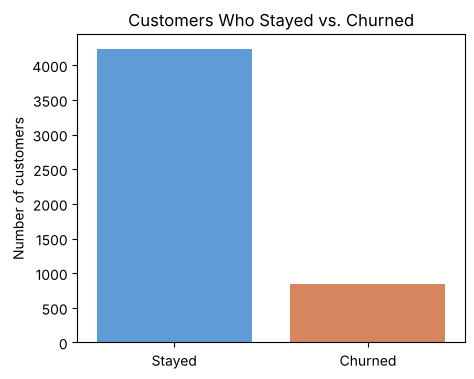

In [2]:
churn_counts = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts()
print(churn_counts)
print("Churn rate: {:.1f}%".format(df["Churn"].mean() * 100))

plt.figure(figsize=(5, 4))
sns.barplot(x=churn_counts.index, y=churn_counts.values, hue=churn_counts.index,
            palette=["#4C9BE8", "#E8804C"], legend=False)
plt.title("Customers Who Stayed vs. Churned")
plt.xlabel("")
plt.ylabel("Number of customers")
plt.show()

In [3]:
df.drop(columns="CustomerID").describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Churn,5073.0,0.17,0.37,0.0,0.00,0.00,0.00,1.00
Tenure,5073.0,10.16,8.40,0.0,3.00,9.00,15.00,61.00
CityTier,5073.0,1.66,0.92,1.0,1.00,1.00,3.00,3.00
WarehouseToHome,5073.0,15.43,8.43,5.0,9.00,13.00,19.00,127.00
HourSpendOnApp,5073.0,2.93,0.71,0.0,2.00,3.00,3.00,5.00
NumberOfDeviceRegistered,5073.0,3.69,1.03,1.0,3.00,4.00,4.00,6.00
SatisfactionScore,5073.0,3.03,1.38,1.0,2.00,3.00,4.00,5.00
NumberOfAddress,5073.0,4.19,2.58,1.0,2.00,3.00,6.00,22.00
Complain,5073.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00
OrderAmountHikeFromlastYear,5073.0,15.68,3.59,11.0,13.00,15.00,18.00,26.00


In [4]:
df.drop(columns="CustomerID").groupby("Churn").mean(numeric_only=True).round(2).T

Churn,0,1
Tenure,11.40,3.91
CityTier,1.62,1.86
WarehouseToHome,15.19,16.65
HourSpendOnApp,2.93,2.95
NumberOfDeviceRegistered,3.63,3.96
SatisfactionScore,2.97,3.34
NumberOfAddress,4.13,4.50
Complain,0.23,0.53
OrderAmountHikeFromlastYear,15.71,15.52
CouponUsed,1.77,1.79


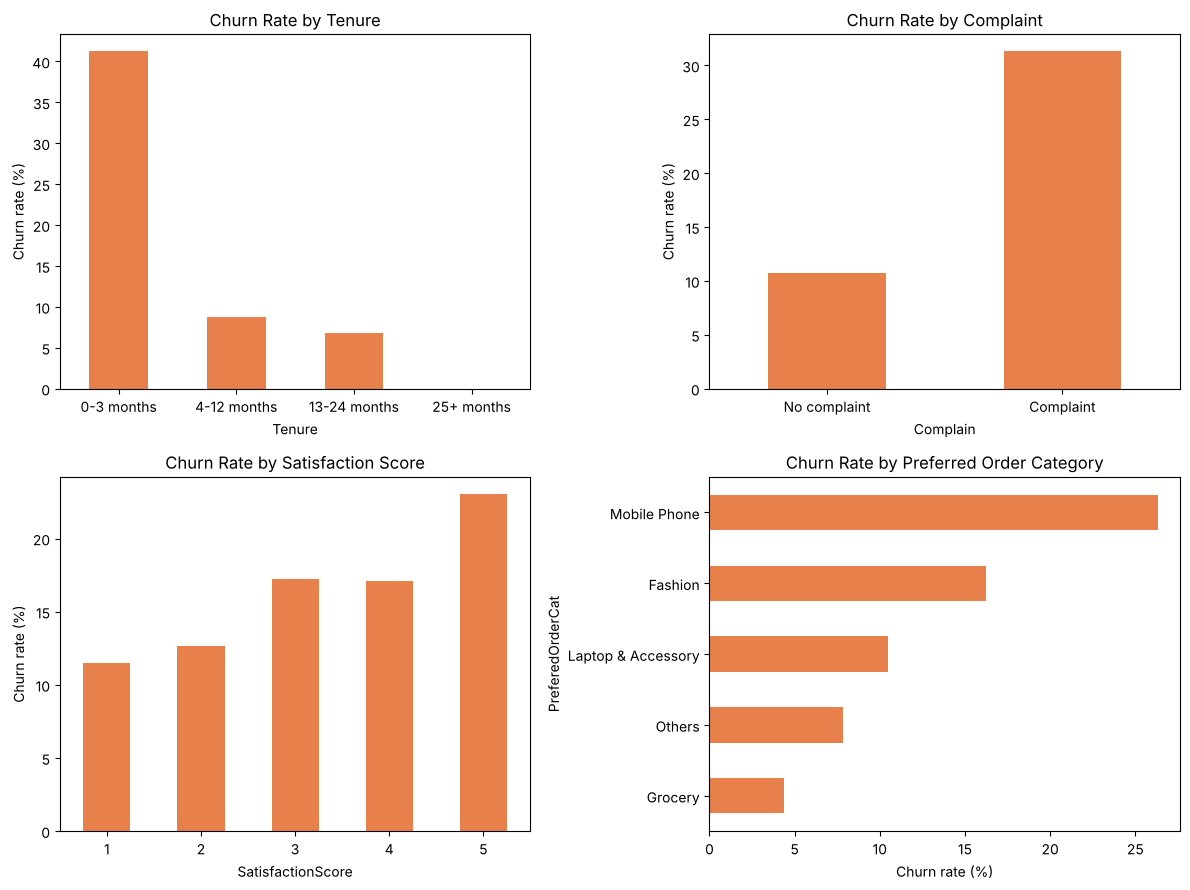

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

tenure_groups = pd.cut(df["Tenure"], bins=[-1, 3, 12, 24, 100],
                       labels=["0-3 months", "4-12 months", "13-24 months", "25+ months"])
(df.groupby(tenure_groups, observed=True)["Churn"].mean() * 100).plot(
    kind="bar", ax=axes[0, 0], color="#E8804C")
axes[0, 0].set_title("Churn Rate by Tenure")

(df.groupby("Complain")["Churn"].mean() * 100).rename({0: "No complaint", 1: "Complaint"}).plot(
    kind="bar", ax=axes[0, 1], color="#E8804C")
axes[0, 1].set_title("Churn Rate by Complaint")

(df.groupby("SatisfactionScore")["Churn"].mean() * 100).plot(
    kind="bar", ax=axes[1, 0], color="#E8804C")
axes[1, 0].set_title("Churn Rate by Satisfaction Score")

(df.groupby("PreferedOrderCat")["Churn"].mean() * 100).sort_values().plot(
    kind="barh", ax=axes[1, 1], color="#E8804C")
axes[1, 1].set_title("Churn Rate by Preferred Order Category")

for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=0)
axes[1, 1].set_xlabel("Churn rate (%)")
plt.tight_layout()
plt.show()

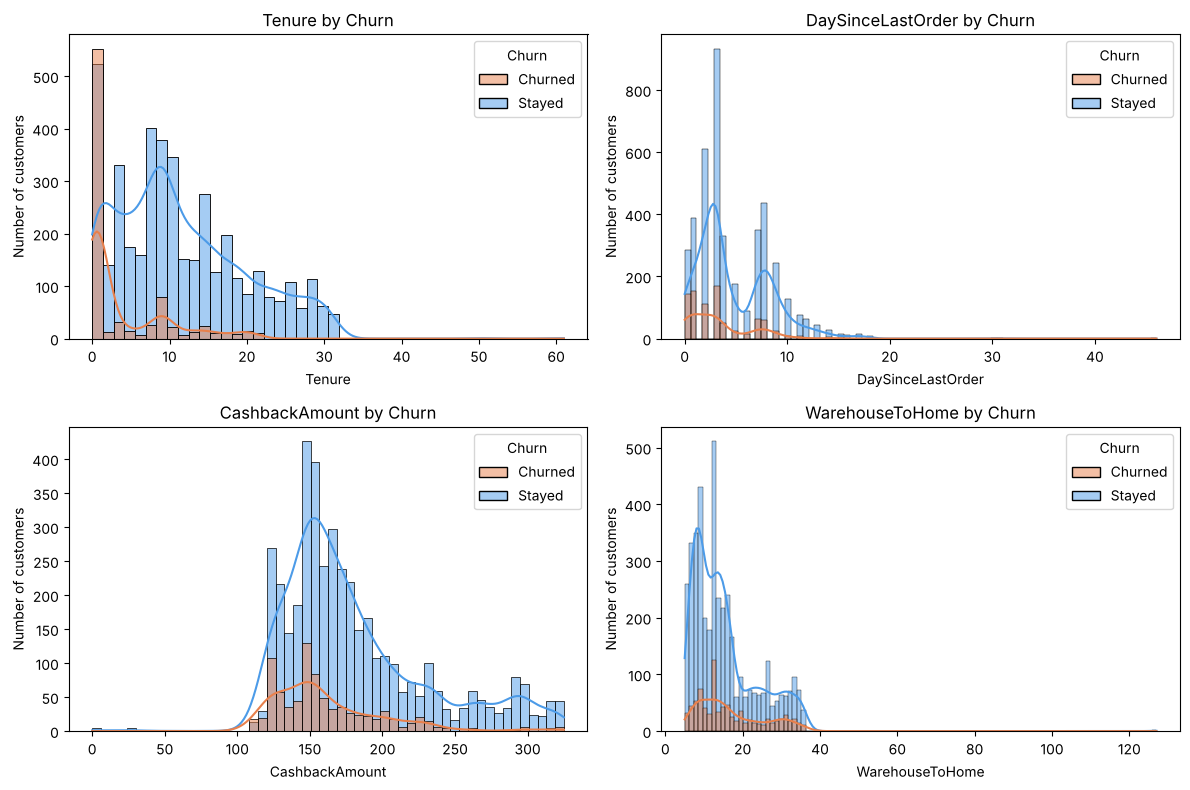

In [6]:
features = ["Tenure", "DaySinceLastOrder", "CashbackAmount", "WarehouseToHome"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.histplot(data=df, x=feat, hue=df["Churn"].map({0: "Stayed", 1: "Churned"}),
                 kde=True, ax=ax, palette={"Stayed": "#4C9BE8", "Churned": "#E8804C"})
    ax.set_title(f"{feat} by Churn")
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

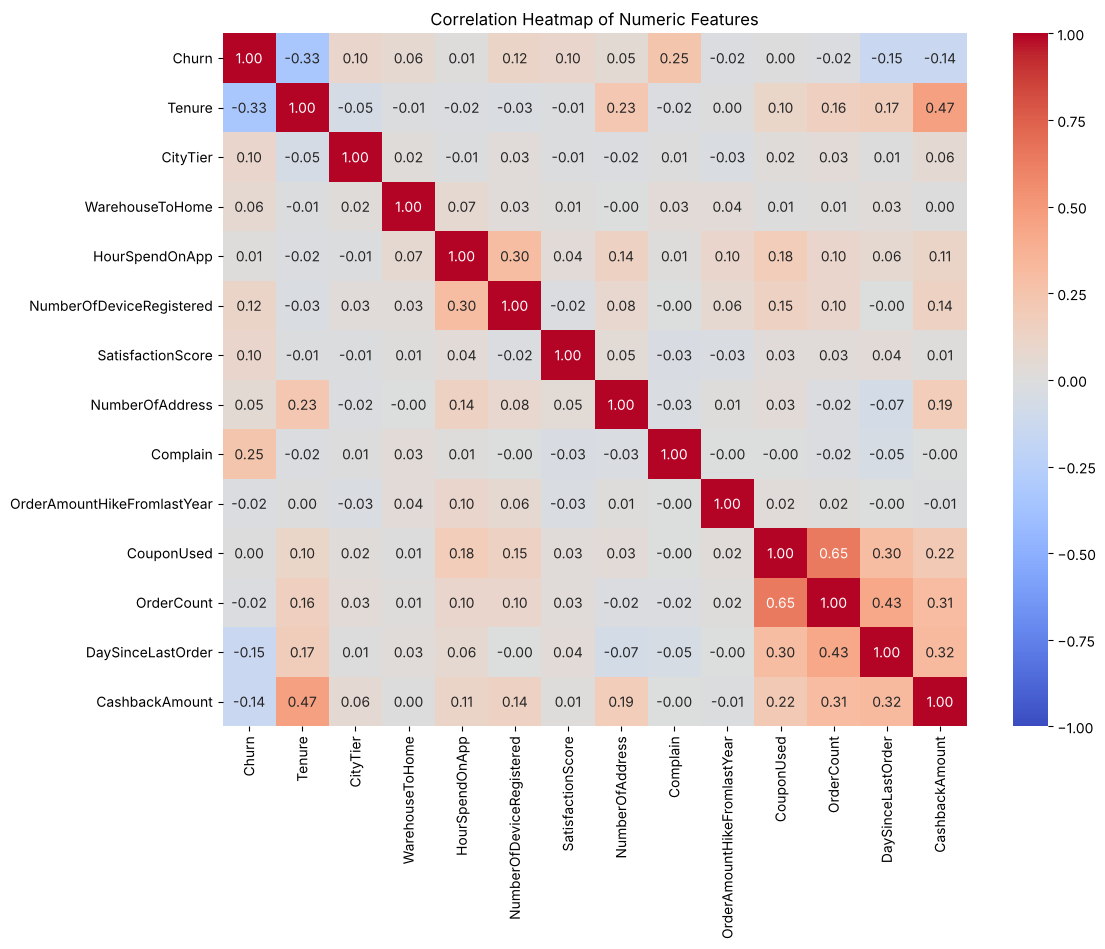

Correlation with Churn:
Complain                       0.249
NumberOfDeviceRegistered       0.117
SatisfactionScore              0.101
CityTier                       0.098
WarehouseToHome                0.065
NumberOfAddress                0.052
HourSpendOnApp                 0.013
CouponUsed                     0.004
OrderCount                    -0.017
OrderAmountHikeFromlastYear   -0.020
CashbackAmount                -0.143
DaySinceLastOrder             -0.148
Tenure                        -0.332
Name: Churn, dtype: float64


In [7]:
numeric = df.drop(columns="CustomerID").select_dtypes("number")
plt.figure(figsize=(12, 9))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

print("Correlation with Churn:")
print(numeric.corr()["Churn"].drop("Churn").sort_values(ascending=False).round(3))

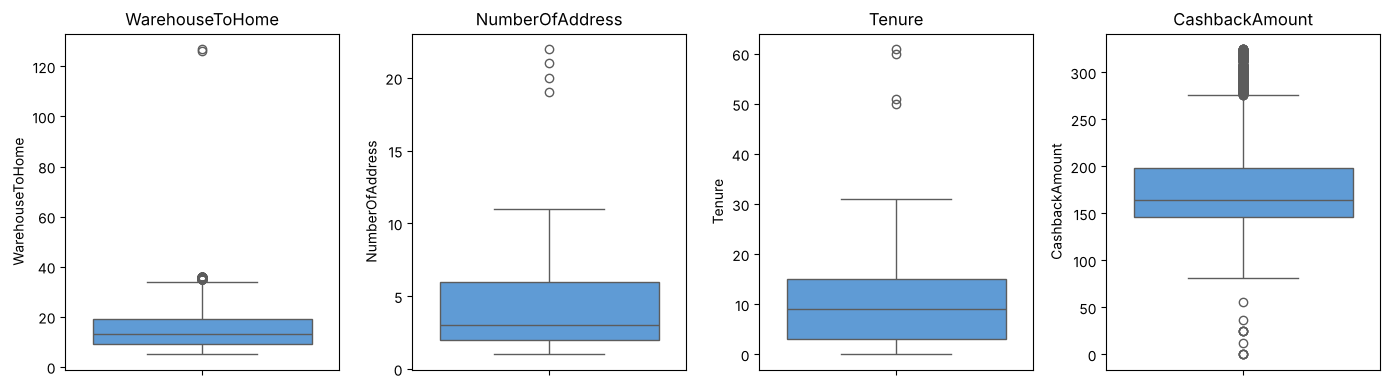

WarehouseToHome: 137 values above 34.0 (max = 127.0)
NumberOfAddress: 4 values above 12.0 (max = 22)
Tenure: 4 values above 33.0 (max = 61.0)
CashbackAmount: 371 values above 276.0 (max = 324.99)


In [8]:
outlier_cols = ["WarehouseToHome", "NumberOfAddress", "Tenure", "CashbackAmount"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C9BE8")
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in outlier_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    high = q3 + 1.5 * (q3 - q1)
    print(f"{col}: {(df[col] > high).sum()} values above {high:.1f} (max = {df[col].max()})")